In [1]:
from advanced_rag.models import get_groq
from advanced_rag.retriever import get_mmr_retriever

In [2]:
llm = get_groq()
mmr_retriever = get_mmr_retriever()

In [4]:
from langchain_classic.retrievers import MultiQueryRetriever

In [5]:
multi_query_retriever = MultiQueryRetriever.from_llm(
    retriever=mmr_retriever, llm=llm, include_original=True
)

In [6]:
res = multi_query_retriever.invoke(
    "what is the future implications of this plan and which state is going to get most benefit from this policy."
)

In [40]:
from langchain_core.prompts import ChatPromptTemplate

prompt_text = """You are an accurate, analytical assistant. Answer the user's question thoroughly using ONLY the facts directly mentioned in the provided Context.

Rules:
1. Grounding: Do not assume, extrapolate, or introduce outside knowledge. Every claim must stem directly from the context.
2. Completeness: Provide a comprehensive answer covering all relevant details present in the text without omitting key aspects.
3. Fallback: If the context does not contain the answer, reply strictly with: "The provided context does not contain enough information to answer this question."
4. Formatting: Structure the final output clearly using clean Markdown (such as bullet points, bold headers, and structured tables where applicable) for optimal readability.
"""

In [41]:
prompt_template = ChatPromptTemplate(
    [("system", prompt_text), ("human", "{context},{input_query}")]
)

In [42]:
llm_chain = prompt_template | llm

In [8]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [10]:
from langchain_core.documents import Document


class MultiQueryState(TypedDict):
    original_query: str
    expanded_context: list[Document]
    final_answer: str

In [11]:
def get_context(state: MultiQueryState):
    query = state["original_query"]
    res = multi_query_retriever.invoke(query)
    return {"expanded_context": res}

In [20]:
def get_final_answer(state: MultiQueryState):
    original_query = state["original_query"]
    context = state["expanded_context"]
    final_res = llm_chain.invoke({"context": context, "input_query": original_query})
    return {"final_answer": final_res}

In [26]:
graph = StateGraph(state_schema=MultiQueryState)

In [27]:
graph.add_node("get_context", get_context)
graph.add_node("get_final_answer", get_final_answer)

In [28]:
graph.add_edge(START, "get_context")
graph.add_edge("get_context", "get_final_answer")
graph.add_edge("get_final_answer", END)

In [29]:
workflow = graph.compile()

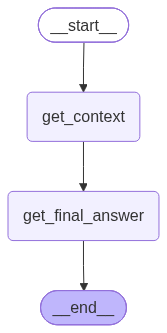

In [30]:
workflow

In [47]:
intial_state = {
    "original_query": "what is this document about and what benefits it will have on india."
}

In [48]:
res = workflow.invoke(intial_state)

In [49]:
from rich import print

print(res["final_answer"].content)

**Document Overview**

| Item | Detail |
|------|--------|
| **Title** | *Roadmap for Ethanol Blending in India: 2020‑2025* |
| **Purpose** | To outline a year‑by‑year plan for the production, supply, marketing, and regulatory environment 
needed to introduce 20 % ethanol‑gasoline blends (E20) across India. |
| **Key Contributors** | NITI Aayog, Ministry of Petroleum & Natural Gas (MoPNG), Society of Indian Automobile 
Manufacturers (SIAM), and other government ministries and experts. |
| **Scope** | 1. Production and supply of ethanol up to 2025‑26. 2. Vehicle‑ and component‑manufacturer impact 
assessment. 3. Environmental impact assessment. 4. Policy recommendations (tax relief, incentives, crop choices). 
5. Roll‑out plan and responsibilities of ministries, states, and industry. |

**Benefits to India**

1. **Economic Savings**
   * A successful E20 program can save the country **US $4 billion per annum** (≈ Rs. 30,000 cr).  
   * Ethanol offers **equivalent engine efficiency at lower cost** than petrol.

2. **Energy Security**
   * Reduces dependence on imported petroleum (India imported 85 % of its oil in 2020‑21).  
   * Utilises domestic agricultural surpluses (food grains, sugarcane) and available technology to produce ethanol.

3. **Environmental Gains**
   * Emission reductions (Table 3.1):
     * **Carbon Monoxide (CO)** – 20 % lower with E10, 50 % lower with E20 (two‑wheelers); 20 % lower with E10, 30 
% lower with E20 (four‑wheelers).  
     * **Hydrocarbons (HC)** – 20 % lower for both E10 and E20 (both vehicle types).  
     * **Oxides of Nitrogen (NOx)** – 10 % higher with E10 (two‑wheelers); no significant change with E20 (both 
vehicle types).  
   * Ethanol is a **less polluting fuel** compared to pure petrol.

4. **Industrial & Agricultural Impact**
   * Enables **vehicle manufacturers** to produce engines compatible with E20 with minimal assembly‑line changes.  
   * **Component manufacturers** will adjust materials (piston rings, piston heads, O‑rings, seals, fuel pumps) but
can produce all required parts domestically.  
   * Encourages cultivation of **lower water‑consuming crops** (e.g., maize) and **second‑generation (2G) 
feedstock** for ethanol production.

5. **Policy & Regulatory Framework**
   * Suggests **price incentives** through retail tax relief on ethanol‑blended fuel.  
   * Proposes **tax incentives** for vehicles compatible with E20.  
   * Outlines responsibilities for union ministries, state governments, and vehicle manufacturers in the rollout 
plan (Figure 9.1).

6. **Strategic Development**
   * Positions India as a **strategic biofuel producer**, promoting “Make in India”, Swachh Bharat, and “Waste to 
Wealth” initiatives.  
   * Supports employment generation and farmer income through expanded biofuel production.

**Summary**

The document is a comprehensive, government‑backed roadmap that details how India can transition to an E20 
ethanol‑gasoline regime by 2025‑